# Clase 8 — Aplicaciones: de la cueva al mundo

**RL a ciegas** · mini curso de aprendizaje por refuerzo · vía profunda

Durante cinco clases el agente aprendió a salir de una cueva. Hoy cambiamos la cueva por problemas reales y vemos que **la receta es siempre la misma**: definir estados, acciones y recompensa, y dejar que un algoritmo encuentre la política.

1. **Marketing digital**: qué anuncio mostrar (bandit multi-brazo, el MDP de un solo paso).
2. **El tutor de IA, versión 2**: el MDP que diseñaron ustedes en la clase 2.
3. **Robótica**: el robot de limpieza que decide si trabajar o ir a cargar batería.
4. **Investigación documental tipo *deep search***: ¿seguir buscando o responder ya?
5. **RLHF**: cómo se entrena ChatGPT con RL.
6. **Proyecto final**: su propio MDP.

> Ejecutar las celdas en orden. Tarda menos de un minuto en CPU.

## Preparación

La primera celda escribe `cave_env.py` (la cueva del curso) para que el notebook funcione solo, también en Colab.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 3 (con modelo): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Imports y semilla fija para que todos veamos los mismos resultados.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)

**Herramientas** (celda plegada): funciones de simulación y de dibujo. No hace falta leerla, solo ejecutarla.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from functools import lru_cache
import pandas as pd

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5, "lines.linewidth": 2,
})


# ================= value iteration (clase 3) =================
def value_iteration(P, R, gamma, valida=None, tol=1e-9):
    """P[s,a,s'], R[s,a]. 'valida[s,a]' marca acciones permitidas. Devuelve V, política, Q."""
    V = np.zeros(P.shape[0])
    while True:
        Q = R + gamma * P @ V
        if valida is not None:
            Q = np.where(valida, Q, -np.inf)
        V_nuevo = Q.max(1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            return V_nuevo, Q.argmax(1), Q
        V = V_nuevo


# ================= 1. bandits =================
def mostrar_ctr(ctr, nombres):
    fig, ax = plt.subplots(figsize=(7, 3))
    bars = ax.bar(nombres, np.array(ctr) * 100, color=COLORES[0], width=0.55)
    bars[int(np.argmax(ctr))].set_color(COLORES[2])
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_ylabel("CTR real (%)"); ax.set_ylim(0, max(ctr) * 130)
    ax.set_title("Lo que el anunciante NO ve: la tasa de clics real de cada anuncio")
    ax.grid(axis="x", visible=False); plt.show()


def correr_bandit(algoritmo, ctr, T=20000, n_campanas=200, seed=0, eps=0.1, c_ucb=0.2, n_ab=500):
    """Simula n_campanas campañas en paralelo. Devuelve regret acumulado medio y % de impresiones al mejor."""
    rng = np.random.default_rng(seed); ctr = np.asarray(ctr); K = len(ctr)
    n = np.zeros((n_campanas, K)); clics = np.zeros((n_campanas, K)); fila = np.arange(n_campanas)
    regret = np.zeros(T); al_mejor = 0.0; elegido_ab = None
    for t in range(T):
        media = clics / np.maximum(n, 1)
        if algoritmo == "A/B fijo":            # reparte parejo n_ab impresiones por anuncio y después se queda con el mejor
            if t < n_ab * K:
                a = np.full(n_campanas, t % K)
            else:
                elegido_ab = media.argmax(1) if elegido_ab is None else elegido_ab
                a = elegido_ab
        elif t < K:                             # los demás: primero muestran cada anuncio una vez
            a = np.full(n_campanas, t)
        elif algoritmo == "ε-greedy":
            a = np.where(rng.random(n_campanas) < eps, rng.integers(K, size=n_campanas), media.argmax(1))
        elif algoritmo == "UCB":
            a = (media + c_ucb * np.sqrt(np.log(t + 1) / n)).argmax(1)
        elif algoritmo == "Thompson":
            a = rng.beta(1 + clics, 1 + n - clics).argmax(1)
        clic = rng.random(n_campanas) < ctr[a]
        n[fila, a] += 1; clics[fila, a] += clic
        regret[t] = (ctr.max() - ctr[a]).mean(); al_mejor += (a == ctr.argmax()).mean()
    return regret.cumsum(), 100 * al_mejor / T


def comparar_bandits(ctr, algoritmos=("A/B fijo", "ε-greedy", "UCB", "Thompson"), **kw):
    res = {alg: correr_bandit(alg, ctr, **kw) for alg in algoritmos}
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
    for k, (alg, (reg, _)) in enumerate(res.items()):
        axs[0].plot(reg, color=COLORES[k], label=alg)
        axs[0].text(len(reg) * 1.01, reg[-1], f"{alg}", va="center", fontsize=10)
    axs[0].set_xlim(0, len(reg) * 1.18)
    axs[0].set_xlabel("impresiones mostradas"); axs[0].set_ylabel("clics perdidos (regret acumulado)")
    axs[0].set_title("Cuántos clics se perdieron por no mostrar siempre el mejor anuncio")
    axs[0].legend(frameon=False, loc="upper left")
    vals = [res[a][1] for a in algoritmos]
    bars = axs[1].bar(algoritmos, vals, color=COLORES[:len(algoritmos)], width=0.6)
    axs[1].bar_label(bars, fmt="%.0f%%", padding=3); axs[1].set_ylim(0, 110)
    axs[1].set_title("% de impresiones dadas al mejor anuncio"); axs[1].grid(axis="x", visible=False)
    plt.tight_layout(); plt.show()
    for alg in algoritmos:
        print(f"{alg:10s}  clics perdidos: {res[alg][0][-1]:6.1f}   impresiones al mejor: {res[alg][1]:4.1f}%")


# ================= 2. tutor como MDP =================
NIVELES = 5                                  # nivel 0 (no sabe) ... 4 (domina)
P_MEJORA_SUMA = 0.5                          # prob. de subir un nivel en suma al practicar suma
def p_mejora_resta(nivel_suma):              # restar es más difícil y se apoya en saber sumar
    return 0.1 + 0.1 * nivel_suma
def p_acierto(nivel):
    return 0.1 + 0.2 * nivel                 # 10% ... 90%


def construir_tutor(recompensa):
    """MDP del tutor. Estado = (nivel suma, nivel resta). Acciones: 0 = suma, 1 = resta."""
    S = NIVELES * NIVELES; P = np.zeros((S, 2, S)); R = np.zeros((S, 2))
    st = lambda ns, nr: ns * NIVELES + nr
    for ns in range(NIVELES):
        for nr in range(NIVELES):
            s = st(ns, nr)
            pm = [P_MEJORA_SUMA if ns < NIVELES - 1 else 0.0, p_mejora_resta(ns) if nr < NIVELES - 1 else 0.0]
            destino = [st(min(ns + 1, NIVELES - 1), nr), st(ns, min(nr + 1, NIVELES - 1))]
            for a in range(2):
                P[s, a, destino[a]] += pm[a]; P[s, a, s] += 1 - pm[a]
                if recompensa == "acierto":       # +1 si acierta, -1 si no (clase 2)
                    R[s, a] = 2 * p_acierto([ns, nr][a]) - 1
                else:                            # "aprendizaje": +1 cada vez que el alumno sube un nivel
                    R[s, a] = pm[a]
    return P, R


def mapas_politica_tutor(politicas):
    fig, axs = plt.subplots(1, len(politicas), figsize=(6.2 * len(politicas), 5))
    cmap = ListedColormap([COLORES[0], COLORES[1], "#dddddd"])
    for ax, (titulo, (pi, Q)) in zip(np.atleast_1d(axs), politicas.items()):
        g = pi.reshape(NIVELES, NIVELES).astype(float).copy()
        empate = np.isclose(Q[:, 0], Q[:, 1]).reshape(NIVELES, NIVELES)
        g[empate] = 2
        ax.imshow(g.T, origin="lower", cmap=cmap, vmin=0, vmax=2)
        for ns in range(NIVELES):
            for nr in range(NIVELES):
                txt = ["suma", "resta", "—"][int(g[ns, nr])]
                ax.text(ns, nr, txt, ha="center", va="center", color="white" if g[ns, nr] < 2 else "#333",
                        fontsize=11, weight="bold")
        ax.plot(0, 0, "s", ms=44, mfc="none", mec="#222", mew=2)
        ax.set_xticks(range(NIVELES)); ax.set_yticks(range(NIVELES)); ax.grid(False)
        ax.set_xlabel("nivel en SUMA"); ax.set_ylabel("nivel en RESTA"); ax.set_title(titulo)
    plt.suptitle("Política óptima del tutor en cada estado (recuadro negro: el alumno al empezar)", y=1.0)
    plt.tight_layout(); plt.show()


def simular_alumnos(pi, n_problemas=40, n_alumnos=300, seed=0):
    rng = np.random.default_rng(seed)
    niveles = np.zeros((n_alumnos, n_problemas + 1, 2)); aciertos = np.zeros(n_alumnos)
    for i in range(n_alumnos):
        ns = nr = 0
        for t in range(n_problemas):
            a = pi[ns * NIVELES + nr]
            aciertos[i] += rng.random() < p_acierto([ns, nr][a])
            if a == 0 and ns < NIVELES - 1 and rng.random() < P_MEJORA_SUMA: ns += 1
            if a == 1 and nr < NIVELES - 1 and rng.random() < p_mejora_resta(ns): nr += 1
            niveles[i, t + 1] = ns, nr
    return niveles.mean(0), aciertos.mean()


def comparar_alumnos(politicas):
    fig, axs = plt.subplots(1, len(politicas), figsize=(6.5 * len(politicas), 3.8), sharey=True)
    for ax, (titulo, pi) in zip(axs, politicas.items()):
        niv, ac = simular_alumnos(pi)
        for k, nombre in enumerate(["suma", "resta"]):
            ax.plot(niv[:, k], color=COLORES[k], label=f"nivel en {nombre}")
        ax.set_title(f"{titulo}\naciertos: {ac:.0f} de {len(niv) - 1} · niveles finales: "
                     f"suma {niv[-1, 0]:.1f}, resta {niv[-1, 1]:.1f}")
        ax.set_xlabel("problema número"); ax.set_ylim(-0.2, NIVELES - 0.6)
        ax.legend(frameon=False, loc="center right")
    axs[0].set_ylabel("nivel promedio (0 a 4)")
    plt.tight_layout(); plt.show()


# ================= 3 y 6. resolver un MDP chico definido con funciones =================
def resolver_mdp(estados, acciones, transicion, gamma=0.9, titulo="Política óptima", mostrar=True):
    """transicion(s, a) -> lista de (probabilidad, s_siguiente, recompensa); lista vacía = acción no permitida."""
    S, A = len(estados), len(acciones); pos = {s: i for i, s in enumerate(estados)}
    P = np.zeros((S, A, S)); R = np.zeros((S, A)); valida = np.zeros((S, A), bool)
    for s in estados:
        for j, a in enumerate(acciones):
            res = transicion(s, a)
            if not res:
                continue
            valida[pos[s], j] = True
            assert abs(sum(p for p, _, _ in res) - 1) < 1e-9, f"las probabilidades de ({s}, {a}) no suman 1"
            for p, s2, r in res:
                P[pos[s], j, pos[s2]] += p; R[pos[s], j] += p * r
    V, pi, Q = value_iteration(P, R, gamma, valida)
    tabla = pd.DataFrame({"estado": estados, "acción óptima": [acciones[k] for k in pi], "valor V(s)": V.round(2)})
    for j, a in enumerate(acciones):
        tabla[f"Q(s, {a})"] = np.where(valida[:, j], Q[:, j].round(2), np.nan)
    if mostrar:
        fig, ax = plt.subplots(figsize=(max(4, 1.3 * S), 1.6))
        cm = ListedColormap(COLORES[:A])
        ax.imshow(pi[None, :], cmap=cm, vmin=-0.5, vmax=A - 0.5, aspect="auto")
        for i in range(S):
            ax.text(i, 0, acciones[pi[i]], ha="center", va="center", color="white", fontsize=11, weight="bold")
        ax.set_xticks(range(S)); ax.set_xticklabels([str(s) for s in estados]); ax.set_yticks([])
        ax.set_xlabel("estado"); ax.set_title(titulo); ax.grid(False)
        for sp in ax.spines.values(): sp.set_visible(False)
        plt.show()
    return tabla


def robot_limpieza(alfa=0.8, beta=0.4, r_limpiar=2.0, r_esperar=1.0, r_rescate=-3.0):
    """Sutton & Barto, ej. 3.3 (recycling robot), con nombres de robot de limpieza."""
    def transicion(s, a):
        if a == "limpiar":
            if s == "alta":
                return [(alfa, "alta", r_limpiar), (1 - alfa, "baja", r_limpiar)]
            return [(beta, "baja", r_limpiar), (1 - beta, "alta", r_rescate)]   # se agota: hay que rescatarlo
        if a == "esperar":
            return [(1.0, s, r_esperar)]
        if a == "cargar":
            return [(1.0, "alta", 0.0)] if s == "baja" else []                  # con batería alta no tiene sentido
    return ["alta", "baja"], ["limpiar", "esperar", "cargar"], transicion


def mapa_politica_robot(gamma=0.9, alfa=0.8, r_limpiar=2.0):
    betas = np.linspace(0, 1, 41); esperas = np.linspace(0, 2.5, 41)
    acc_baja = np.zeros((len(esperas), len(betas)))
    for i, rw in enumerate(esperas):
        for j, b in enumerate(betas):
            est, acc, tr = robot_limpieza(alfa, b, r_limpiar, rw)
            t = resolver_mdp(est, acc, tr, gamma, mostrar=False)
            acc_baja[i, j] = acc.index(t["acción óptima"][1])
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.imshow(acc_baja, origin="lower", cmap=ListedColormap(COLORES[:3]), vmin=-0.5, vmax=2.5, aspect="auto",
              extent=[betas[0], betas[-1], esperas[0], esperas[-1]])
    ax.grid(False)
    for k, nombre in enumerate(["limpiar", "esperar", "cargar"]):
        yy, xx = np.argwhere(acc_baja == k).mean(0) if (acc_baja == k).any() else (np.nan, np.nan)
        if not np.isnan(xx):
            ax.text(betas[int(xx)], esperas[int(yy)], nombre, ha="center", va="center", color="white",
                    fontsize=14, weight="bold")
    ax.set_xlabel("β: probabilidad de NO agotarse limpiando con batería baja")
    ax.set_ylabel("recompensa por esperar")
    ax.set_title(f"¿Qué hace el robot con batería BAJA? (limpiar rinde {r_limpiar:g})")
    plt.show()


# ================= 4. deep search como MDP =================
MAX_BUSQUEDAS, MAX_CONF = 5, 4
P_RELEVANTE = [0.9, 0.75, 0.6, 0.45, 0.3]       # el 1er documento suele ser bueno; los siguientes, cada vez menos
P_ACIERTO_CONF = [0.25, 0.55, 0.75, 0.88, 0.95] # prob. de responder bien según la confianza (0 = adivinar entre 4)
ACC_DS = ["buscar", "leer", "responder"]


def acciones_validas(q, d, c):
    return np.array([q < MAX_BUSQUEDAS, d < q, True])      # solo se puede leer lo que ya se encontró


def paso_ds(estado, a, costo, rng):
    q, d, c = estado
    if a == 2:
        return None, float(rng.random() < P_ACIERTO_CONF[c])   # fin: +1 si la respuesta es correcta
    if a == 0:
        q += 1
    else:
        if rng.random() < P_RELEVANTE[d]:
            c = min(c + 1, MAX_CONF)
        d += 1
    return (q, d, c), -costo


def q_learning_ds(costo, episodios=30000, seed=0):
    """Q-learning tabular. Tasa de aprendizaje 1/N^0.7: grande en lo poco visitado, chica en lo muy visitado."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((MAX_BUSQUEDAS + 1, MAX_BUSQUEDAS + 1, MAX_CONF + 1, 3)); N = np.zeros_like(Q)
    for ep in range(episodios):
        eps = max(0.05, 1 - ep / (0.6 * episodios)); est = (0, 0, 0)
        while est is not None:
            v = acciones_validas(*est)
            a = rng.choice(np.flatnonzero(v)) if rng.random() < eps else np.where(v, Q[est], -np.inf).argmax()
            est2, r = paso_ds(est, a, costo, rng)
            objetivo = r if est2 is None else r + np.where(acciones_validas(*est2), Q[est2], -np.inf).max()
            N[est + (a,)] += 1
            Q[est + (a,)] += (objetivo - Q[est + (a,)]) / N[est + (a,)] ** 0.7
            est = est2
    return Q


def jugar_ds(Q, costo, rng):
    est = (0, 0, 0); pasos = []; G = 0.0
    while True:
        a = np.where(acciones_validas(*est), Q[est], -np.inf).argmax()
        pasos.append((est, ACC_DS[a]))
        est2, r = paso_ds(est, a, costo, rng); G += r
        if est2 is None:
            return pasos, r, G
        est = est2


def evaluar_ds(Q, costo, n=5000, seed=1):
    rng = np.random.default_rng(seed); L, A, G = [], [], []
    for _ in range(n):
        pasos, acierto, g = jugar_ds(Q, costo, rng)
        L.append(len(pasos) - 1); A.append(acierto); G.append(g)
    return np.mean(L), np.mean(A), np.mean(G)


def optimo_ds(costo):
    """Valor óptimo exacto (programación dinámica), para comparar con lo que aprendió Q-learning."""
    @lru_cache(None)
    def V(q, d, c):
        mejor = P_ACIERTO_CONF[c]
        if q < MAX_BUSQUEDAS: mejor = max(mejor, -costo + V(q + 1, d, c))
        if d < q:
            p = P_RELEVANTE[d]
            mejor = max(mejor, -costo + p * V(q, d + 1, min(c + 1, MAX_CONF)) + (1 - p) * V(q, d + 1, c))
        return mejor
    return V(0, 0, 0)


def barrido_costos(costos):
    filas = []
    for k in costos:
        Q = q_learning_ds(k)
        filas.append((k,) + evaluar_ds(Q, k) + (optimo_ds(k),))
    return np.array(filas)


def grafico_tradeoff(res):
    costo, pasos, acierto, neto, opt = res.T
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.9))
    axs[0].plot(costo, pasos, "o-", color=COLORES[0], ms=8)
    axs[0].set_ylabel("pasos antes de responder"); axs[0].set_title("Cuánto investiga")
    axs[1].plot(costo, acierto * 100, "o-", color=COLORES[1], ms=8)
    axs[1].set_ylabel("% de respuestas correctas"); axs[1].set_title("Qué tan bien responde")
    axs[1].set_ylim(0, 100)
    axs[2].plot(costo, neto, "o-", color=COLORES[2], ms=8, label="Q-learning")
    axs[2].plot(costo, opt, "--", color="#555", lw=1.5, label="óptimo exacto")
    axs[2].set_ylabel("recompensa neta"); axs[2].set_title("Acierto − costo total")
    axs[2].legend(frameon=False)
    for ax in axs: ax.set_xlabel("costo por paso")
    plt.tight_layout(); plt.show()


def mostrar_trayectoria(costo, seed=3):
    Q = q_learning_ds(costo)
    pasos, acierto, G = jugar_ds(Q, costo, np.random.default_rng(seed))
    print(f"costo por paso = {costo}:")
    for (q, d, c), a in pasos:
        print(f"   búsquedas={q} leídos={d} confianza={c}  ->  {a}")
    print(f"   respuesta {'correcta' if acierto else 'incorrecta'} · recompensa total {G:+.2f}\n")


# ================= 5. RLHF =================
def diagrama_rlhf():
    fig, ax = plt.subplots(figsize=(14, 3.6)); ax.set_xlim(0, 14); ax.set_ylim(0, 4.2); ax.axis("off")
    cajas = [
        (0.2, "1. Ajuste supervisado\n(SFT)", "personas escriben\nrespuestas modelo", COLORES[0]),
        (4.9, "2. Modelo de recompensa", "personas ordenan respuestas:\nA mejor que B → aprende r(x, y)", COLORES[1]),
        (9.6, "3. RL (PPO)", "el modelo genera, r(x, y) puntúa,\nPPO ajusta la política", COLORES[2]),
    ]
    for x, tit, sub, col in cajas:
        ax.add_patch(mpatches.FancyBboxPatch((x, 1.0), 4.1, 2.3, boxstyle="round,pad=0.08", fc=col, ec="none", alpha=0.18))
        ax.text(x + 2.05, 2.75, tit, ha="center", va="center", fontsize=13, weight="bold")
        ax.text(x + 2.05, 1.65, sub, ha="center", va="center", fontsize=10.5, color="#444")
    fl = dict(arrowstyle="-|>", lw=2, color="#333", mutation_scale=18)
    ax.annotate("", xy=(4.85, 2.15), xytext=(4.35, 2.15), arrowprops=fl)
    ax.annotate("", xy=(9.55, 2.15), xytext=(9.05, 2.15), arrowprops=fl)
    ax.text(11.65, 0.45, "agente = el modelo de lenguaje · acción = la respuesta · recompensa = r(x, y)",
            ha="center", fontsize=10.5, color="#333")
    ax.set_title("RLHF: cómo se pasa de un modelo que completa texto a un asistente", fontsize=13)
    plt.show()

## 0. Lo que ya sabemos, en una figura

La cueva resuelta con *value iteration* (clase 3): el color es el valor $V(s)$ de cada casilla y las flechas, la política. Todo lo que sigue es **esto mismo con otros estados, acciones y recompensas**.

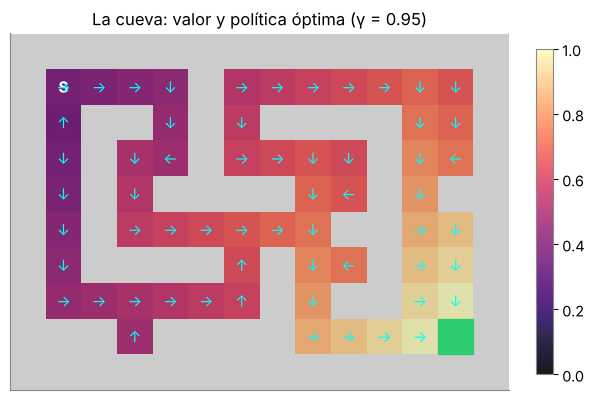

In [4]:
env = CaveEnv()
V_cueva, pi_cueva, _ = value_iteration(env.P, env.R, gamma=0.95)
env.plot(values=V_cueva, policy=pi_cueva, title="La cueva: valor y política óptima (γ = 0.95)")
plt.show()

| | Cueva | Marketing | Tutor | Robot | Deep search |
|---|---|---|---|---|---|
| **Estado** | casilla | (uno solo) | nivel del alumno | batería | lo investigado |
| **Acción** | ↑ → ↓ ← | qué anuncio | suma / resta | limpiar / esperar / cargar | buscar / leer / responder |
| **Recompensa** | +1 en la salida | +1 por clic | +1 por nivel aprendido | trabajo hecho | acierto − costo |

## 1. Marketing digital: el bandit multi-brazo

Una tienda online tiene **4 anuncios** y cada vez que alguien entra a la página debe mostrar uno. Cada anuncio tiene una tasa de clics (*click-through rate*, CTR) que **nadie conoce**. Cada impresión es una tragamonedas: tiro de una palanca (*arm*) y gano o no gano un clic. De ahí el nombre: **bandit multi-brazo** (*multi-armed bandit*).

### Paso 1 — Lo que no se ve

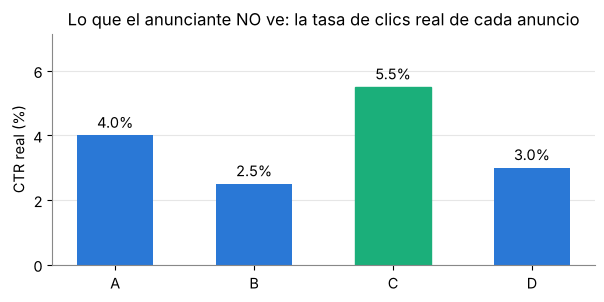

In [5]:
ANUNCIOS = ["A", "B", "C", "D"]
CTR_OCULTOS = [0.040, 0.025, 0.055, 0.030]     # el mejor es C, pero el algoritmo no lo sabe
mostrar_ctr(CTR_OCULTOS, ANUNCIOS)

Las diferencias son de 1 o 2 clics cada 100 impresiones: hacen falta **miles** de impresiones para distinguir un anuncio de otro.

**¿Por qué es RL?** Es el MDP más chico posible: **un solo estado** (la página siempre es la misma), y cada episodio dura **un solo paso** (una impresión). No hay consecuencias demoradas: lo único que queda del problema de RL es el **dilema exploración–explotación** de la clase 5.

### Paso 2 — Cuatro estrategias

- **A/B fijo**: mostrar cada anuncio 500 veces por igual y después quedarse para siempre con el que tuvo más clics. Es lo que se hace tradicionalmente.
- **ε-greedy** (clase 5): el 90% de las veces mostrar el mejor hasta ahora; el 10%, uno al azar.
- **UCB** (*upper confidence bound*): mostrar el que tiene el mejor "optimista" = promedio + bonus por incertidumbre. Lo poco probado recibe el beneficio de la duda.
- **Thompson sampling**: para cada anuncio imaginar un CTR plausible según los datos (una distribución Beta) y mostrar el que salió más alto. Explora más cuando hay más duda.

Medimos el **regret**: los clics que se perdieron por no haber mostrado siempre el mejor anuncio.

$$\text{regret}_T = \sum_{t=1}^{T} \big(\mu^* - \mu_{a_t}\big)$$

donde $\mu^*$ es el CTR del mejor anuncio y $\mu_{a_t}$ el del anuncio mostrado. Simulamos 200 campañas de 20.000 impresiones cada una.

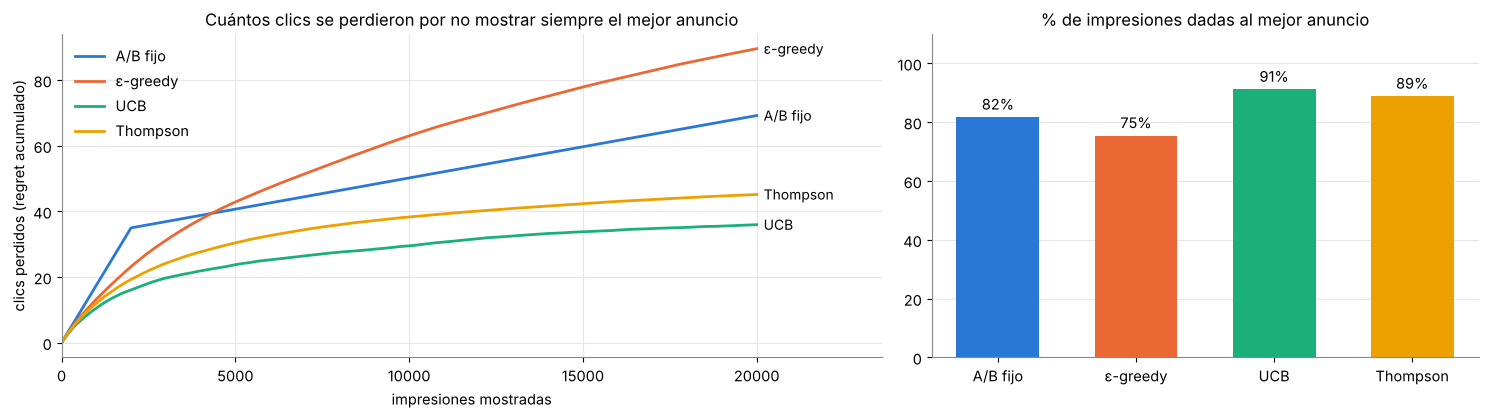

A/B fijo    clics perdidos:   69.2   impresiones al mejor: 81.7%
ε-greedy    clics perdidos:   89.6   impresiones al mejor: 75.4%
UCB         clics perdidos:   36.0   impresiones al mejor: 91.1%
Thompson    clics perdidos:   45.2   impresiones al mejor: 88.8%


In [6]:
comparar_bandits(CTR_OCULTOS, T=20000, n_campanas=200, seed=SEMILLA)

**Qué mirar:**

- **A/B fijo** pierde clics a ritmo constante durante la prueba (la mitad del tráfico va a anuncios malos) y, si se equivoca al elegir, sigue perdiendo para siempre.
- **ε-greedy** nunca deja de explorar: su curva sigue subiendo en línea recta, porque un 10% de las impresiones siempre se desperdicia.
- **UCB** y **Thompson** exploran más al principio y casi nada al final: la curva se aplana, y el ~90% de las impresiones va al mejor anuncio. (UCB gana por poco porque le ajustamos el bonus a CTR tan chicos; Thompson no necesita ningún ajuste.)

Por eso las plataformas de anuncios y de recomendación usan bandits en vez de pruebas A/B fijas.

### ✍️ Ejercicio

1. Cambien `c_ucb` a `1.41` (el valor "de libro", $\sqrt{2}$). ¿Por qué UCB explora de más cuando los CTR son tan chicos?
2. Cambien los CTR para que los anuncios sean muy distintos (por ejemplo `[0.01, 0.02, 0.10, 0.03]`). ¿Sigue convenciendo el A/B fijo?

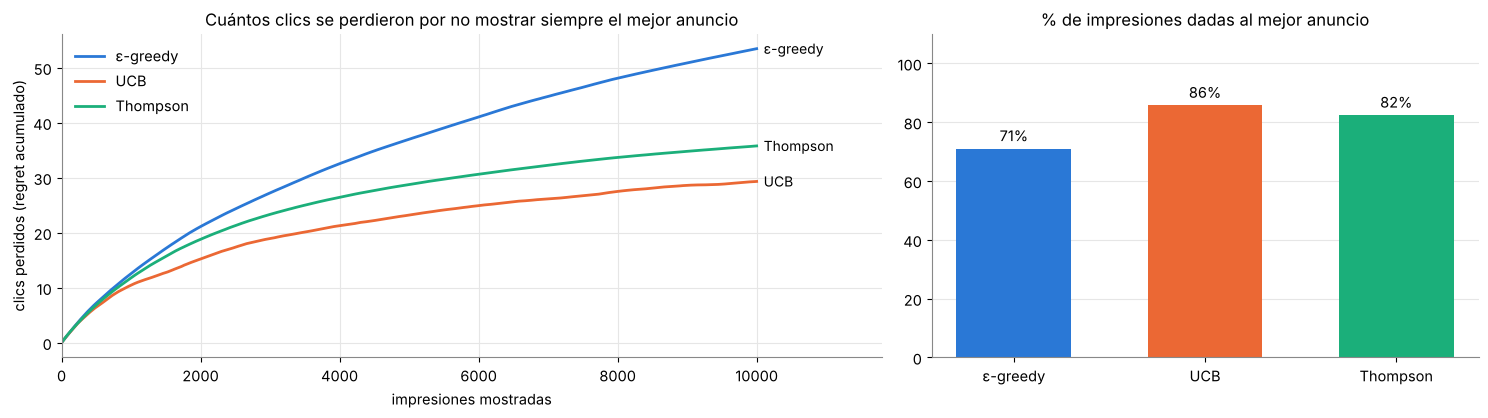

ε-greedy    clics perdidos:   53.5   impresiones al mejor: 71.0%
UCB         clics perdidos:   29.3   impresiones al mejor: 85.7%
Thompson    clics perdidos:   35.8   impresiones al mejor: 82.4%


In [7]:
# TODO: cambiar c_ucb y/o los CTR y volver a ejecutar
c_ucb = 0.2
ctr_ejercicio = [0.040, 0.025, 0.055, 0.030]

comparar_bandits(ctr_ejercicio, algoritmos=("ε-greedy", "UCB", "Thompson"), T=10000, n_campanas=100, c_ucb=c_ucb)

## 2. El tutor de IA, versión 2: el MDP que diseñaron ustedes

En la clase 2 vimos que con recompensa **+1 por acierto / −1 por error**, el tutor aprende a dar **solo sumas** (*reward hacking*). Ahora tomamos el rediseño de los alumnos y lo resolvemos con *value iteration*.

**El MDP:**

- **Estado**: nivel estimado del alumno en suma y en resta, discretizado de 0 (no sabe) a 4 (domina): 5 × 5 = 25 estados.
- **Acción**: dar un problema de **suma** o de **resta**.
- **Dinámica**: al practicar suma, sube un nivel con probabilidad 0.5. Al practicar resta, la probabilidad de subir es baja y **crece con el nivel de suma** (restar se apoya en saber sumar): 0.1 + 0.1 × nivel de suma.
- **Recompensa**, dos versiones:
  - *acierto* (la de la clase 2): +1 / −1 según la respuesta;
  - *aprendizaje* (la rediseñada): **+1 cada vez que el alumno sube un nivel**, en lo que sea.

### Paso 1 — Resolver los dos MDP y comparar las políticas

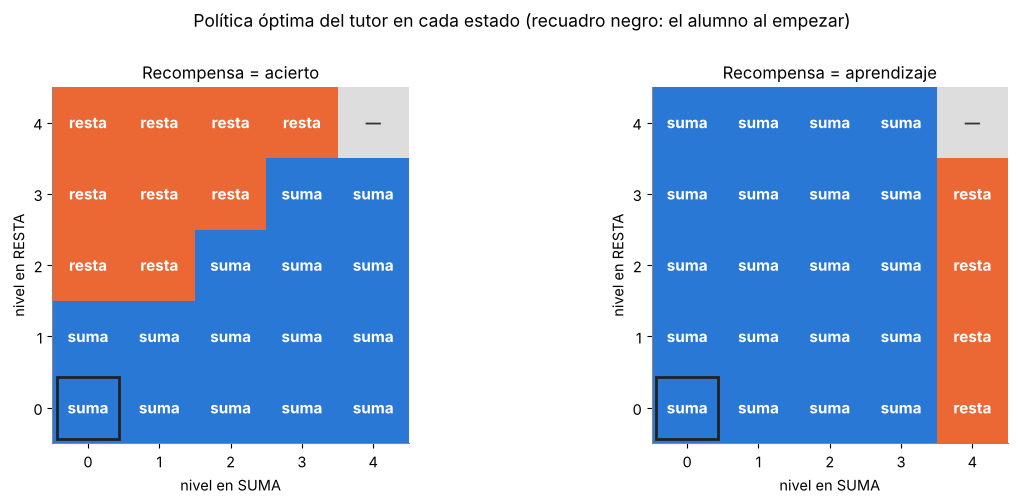

In [8]:
gamma_tutor = 0.9
politicas_tutor = {}
for recompensa in ["acierto", "aprendizaje"]:
    P_t, R_t = construir_tutor(recompensa)
    V_t, pi_t, Q_t = value_iteration(P_t, R_t, gamma_tutor)
    politicas_tutor[f"Recompensa = {recompensa}"] = (pi_t, Q_t)

mapas_politica_tutor(politicas_tutor)

Cada casilla es un estado; el texto es lo que el tutor elige ahí. Partimos del recuadro negro (0, 0) y el alumno se mueve hacia la derecha cuando aprende a sumar y hacia arriba cuando aprende a restar. "—" marca el estado donde las dos acciones valen lo mismo (el alumno ya domina todo).

- **Recompensa = acierto**: desde el inicio, siempre "suma". El alumno se mueve solo por la fila de abajo: nunca aprende a restar. Las casillas "resta" de arriba a la izquierda son estados a los que este tutor nunca llega.
- **Recompensa = aprendizaje**: primero suma (porque se aprende rápido **y** porque prepara para restar), y **en cuanto el alumno domina la suma, pasa a restas**.

### Paso 2 — Seguir a 300 alumnos simulados durante 40 problemas

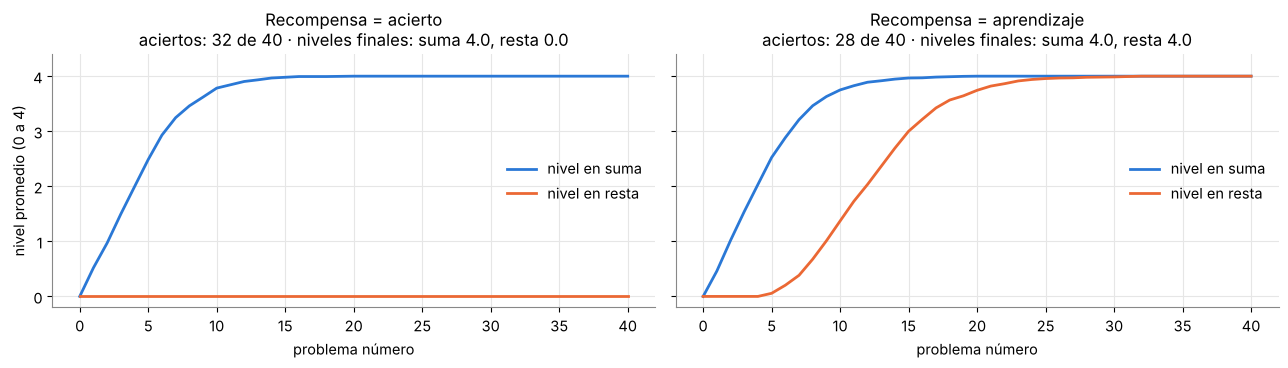

In [9]:
comparar_alumnos({nombre: pi for nombre, (pi, Q) in politicas_tutor.items()})

Con la recompensa de acierto el alumno acierta más problemas… y no aprende a restar. Con la recompensa de aprendizaje acierta menos (las restas cuestan), pero termina sabiendo las dos cosas. **El algoritmo es el mismo; lo que cambió es qué le pedimos.**

Ojo: en la vida real el nivel no se observa directamente. Un tutor real tendría que **estimarlo** a partir de los aciertos (los sistemas de tutoría usan modelos como *Bayesian knowledge tracing*). Es el mismo problema de "historia vs. estado" de la clase 2.

### ✍️ Ejercicio

Cambien la dificultad de la resta: por ejemplo, que no dependa de la suma (`return 0.3`) o que dependa mucho más (`return 0.05 + 0.2 * nivel_suma`). ¿En qué estados cambia la política?

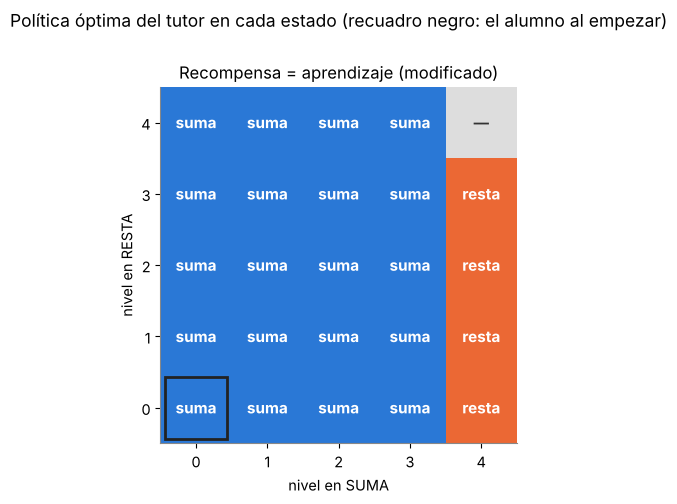

In [10]:
def p_mejora_resta(nivel_suma):
    return 0.1 + 0.1 * nivel_suma        # TODO: cambiar y volver a ejecutar

P_t, R_t = construir_tutor("aprendizaje")
V_t, pi_t, Q_t = value_iteration(P_t, R_t, gamma_tutor)
mapas_politica_tutor({"Recompensa = aprendizaje (modificado)": (pi_t, Q_t)})

## 3. Robótica: el robot de limpieza

Un clásico de Sutton & Barto (ejemplo 3.3, el *recycling robot*), contado como robot de limpieza. El robot tiene la batería **alta** o **baja**, y en cada turno decide:

- **limpiar**: rinde 2 puntos, pero gasta batería. Con batería alta, sigue alta con probabilidad α; con batería baja, puede **agotarse** (probabilidad 1 − β): hay que ir a rescatarlo (−3) y vuelve cargado.
- **esperar**: rinde 1 punto (alguien le acerca basura) y no gasta batería.
- **cargar** (solo con batería baja): vuelve a alta, 0 puntos.

Es un MDP de 2 estados y 3 acciones: lo resolvemos con *value iteration* usando la herramienta `resolver_mdp`, que también van a usar en el proyecto final.

### Paso 1 — La tabla de la política

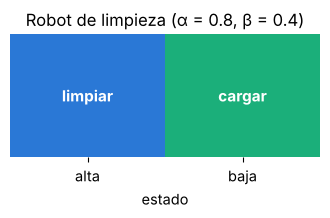

,estado,acción óptima,valor V(s),"Q(s, limpiar)","Q(s, esperar)","Q(s, cargar)"
0,alta,limpiar,16.95,16.95,16.25,NaN
1,baja,cargar,15.25,13.64,14.73,15.25


In [11]:
estados_r, acciones_r, transicion_r = robot_limpieza(alfa=0.8, beta=0.4, r_limpiar=2, r_esperar=1)
tabla_robot = resolver_mdp(estados_r, acciones_r, transicion_r, gamma=0.9, titulo="Robot de limpieza (α = 0.8, β = 0.4)")
tabla_robot

Con batería alta, limpia. Con batería baja, **va a cargar**: arriesgarse a quedar varado (60% de probabilidad, −3) no vale la pena. La tabla muestra también los valores $Q(s, a)$: cuánto vale cada acción en cada estado; "cargar" con batería alta no está permitida (NaN).

### Paso 2 — ¿Cuándo cambia la decisión?

Variamos β (qué tan seguido sobrevive el robot si limpia con batería baja) y la recompensa por esperar, y pintamos la acción óptima con batería baja.

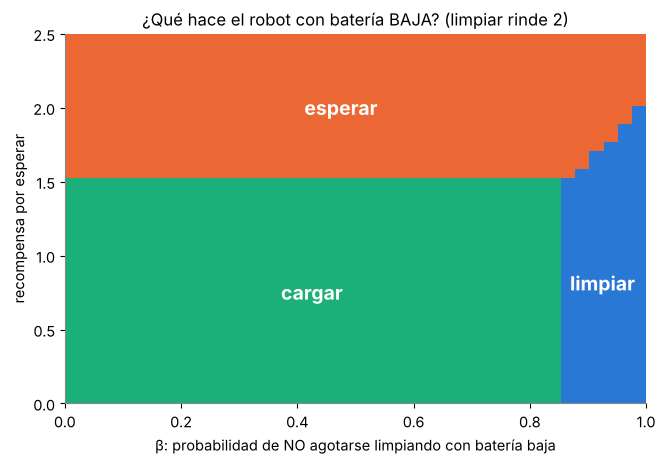

In [12]:
mapa_politica_robot(gamma=0.9, alfa=0.8, r_limpiar=2)

Tres regiones con sentido común:

- si limpiar con batería baja casi nunca agota al robot (β alto), **limpia**;
- si esperar rinde bastante (en este caso, más de 1.5 de los 2 puntos que da limpiar), **espera**: no arriesga y no pierde un turno cargando;
- en el resto, **carga**.

Nadie programó estas reglas: salen de resolver el MDP. Los robots reales tienen estados continuos (posición, velocidad, ángulos) y se resuelven con Deep RL (clase 6), muchas veces primero en simulación.

### ✍️ Ejercicio

Cambien `r_rescate` (lo que cuesta rescatar al robot) a `-10` o a `0`. ¿Qué pasa con la decisión en batería baja?

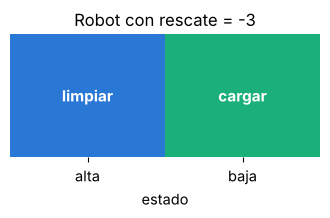

,estado,acción óptima,valor V(s),"Q(s, limpiar)","Q(s, esperar)","Q(s, cargar)"
0,alta,limpiar,16.95,16.95,16.25,NaN
1,baja,cargar,15.25,13.64,14.73,15.25


In [13]:
r_rescate = -3      # TODO: probar -10 y 0
est, acc, tr = robot_limpieza(alfa=0.8, beta=0.4, r_limpiar=2, r_esperar=1, r_rescate=r_rescate)
resolver_mdp(est, acc, tr, gamma=0.9, titulo=f"Robot con rescate = {r_rescate}")

## 4. Investigación documental tipo *deep search*

Los asistentes que "investigan" (*deep research*, *deep search*) hacen un ciclo: buscan, leen, deciden si ya saben lo suficiente y responden. Cada paso cuesta (tiempo, dinero, tokens). Un MDP de juguete:

- **Estado**: (búsquedas hechas, documentos leídos, confianza de 0 a 4).
- **Acciones**:
  - **buscar**: encuentra un documento nuevo (máximo 5);
  - **leer**: lee el próximo documento encontrado; si es relevante, la confianza sube 1. Los primeros resultados suelen ser buenos (90% relevantes) y los siguientes, cada vez menos (hasta 30%);
  - **responder**: termina el episodio.
- **Recompensa**: **+1 si la respuesta es correcta** (más probable cuanto mayor la confianza: de 25%, adivinar entre 4, a 95%) **menos un costo por cada paso** de buscar o leer.

El agente **no conoce** estas probabilidades: aprende con **Q-learning tabular** (clase 4), solo jugando.

### Paso 1 — Una investigación con costo bajo y otra con costo alto

In [14]:
mostrar_trayectoria(costo=0.01)
mostrar_trayectoria(costo=0.08)

costo por paso = 0.01:
   búsquedas=0 leídos=0 confianza=0  ->  buscar
   búsquedas=1 leídos=0 confianza=0  ->  buscar
   búsquedas=2 leídos=0 confianza=0  ->  buscar
   búsquedas=3 leídos=0 confianza=0  ->  buscar
   búsquedas=4 leídos=0 confianza=0  ->  leer
   búsquedas=4 leídos=1 confianza=1  ->  leer
   búsquedas=4 leídos=2 confianza=2  ->  leer
   búsquedas=4 leídos=3 confianza=2  ->  leer
   búsquedas=4 leídos=4 confianza=2  ->  buscar
   búsquedas=5 leídos=4 confianza=2  ->  leer
   búsquedas=5 leídos=5 confianza=3  ->  responder
   respuesta correcta · recompensa total +0.90



costo por paso = 0.08:
   búsquedas=0 leídos=0 confianza=0  ->  buscar
   búsquedas=1 leídos=0 confianza=0  ->  leer
   búsquedas=1 leídos=1 confianza=1  ->  buscar
   búsquedas=2 leídos=1 confianza=1  ->  leer
   búsquedas=2 leídos=2 confianza=2  ->  responder
   respuesta incorrecta · recompensa total -0.32



Con costo bajo, el agente busca y lee casi todo antes de responder. Con costo alto, lee uno o dos documentos (los mejores) y responde.

### Paso 2 — El trade-off "seguir buscando vs. responder ya"

Entrenamos Q-learning para varios costos por paso (30.000 episodios cada uno) y medimos la política aprendida en 5.000 investigaciones. La línea punteada es el óptimo exacto calculado con programación dinámica, para chequear que Q-learning aprendió bien.

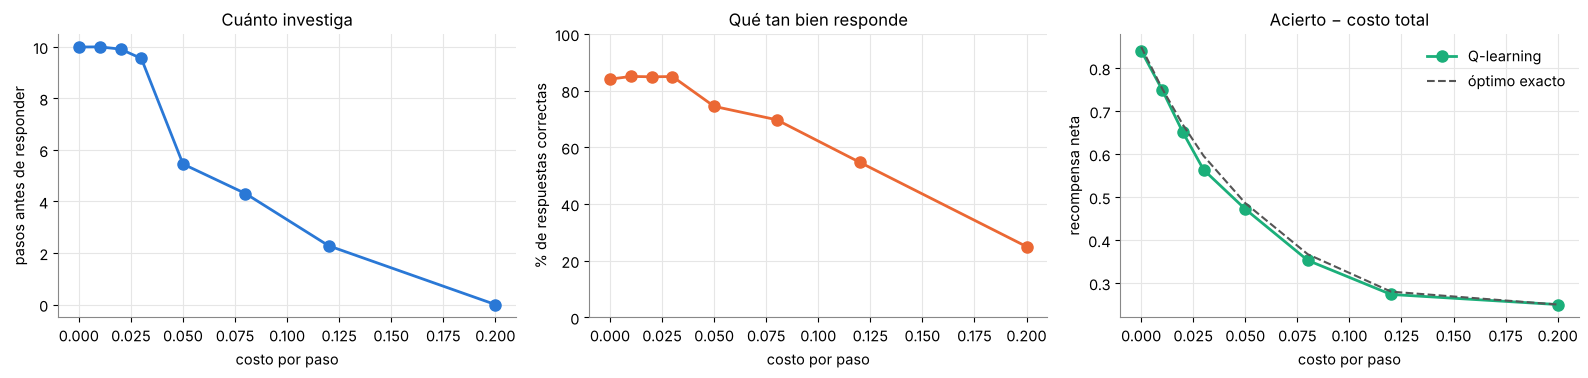

In [15]:
costos = [0.0, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.2]
resultados_ds = barrido_costos(costos)
grafico_tradeoff(resultados_ds)

A medida que cada paso cuesta más, el agente **investiga menos** y **acierta menos**, pero su recompensa neta es la mejor posible para ese costo (coincide con el óptimo). Con costo muy alto, responde de entrada y adivina (25%).

**Puente a los agentes de LLM.** Un agente que usa herramientas (buscar en la web, leer un PDF, ejecutar código) es exactamente esto, con un estado enorme (todo el texto de la conversación) y una política que es un modelo de lenguaje. Los sistemas de *deep research* se entrenan con RL usando como recompensa si la respuesta final es correcta, y el costo por paso (o un límite de pasos) es lo que les enseña a no buscar para siempre. Las mismas preguntas de diseño aparecen: ¿cómo se mide "correcta"? ¿cuánto cuesta un paso? ¿qué hace el agente si la recompensa se puede engañar?

### ✍️ Ejercicio

Hagan que los documentos sean igual de buenos siempre (`P_RELEVANTE = [0.6] * 5`) y vuelvan a ejecutar el barrido. ¿El trade-off sigue siendo gradual o pasa a ser "todo o nada"? ¿Por qué?

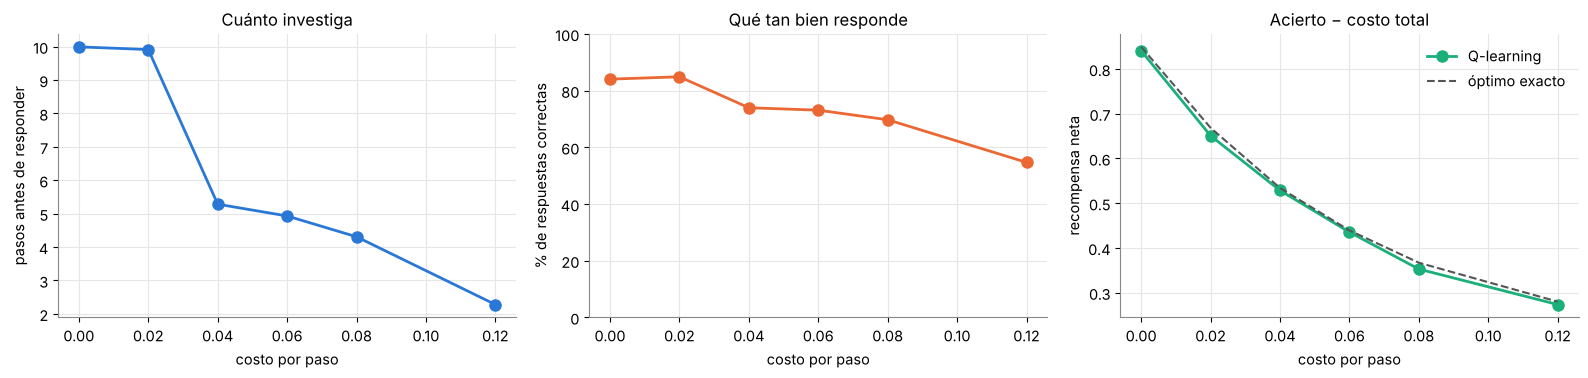

In [16]:
P_RELEVANTE = [0.9, 0.75, 0.6, 0.45, 0.3]     # TODO: probar [0.6] * 5
grafico_tradeoff(barrido_costos([0.0, 0.02, 0.04, 0.06, 0.08, 0.12]))

## 5. RLHF: ChatGPT, el mejor ejemplo de RL

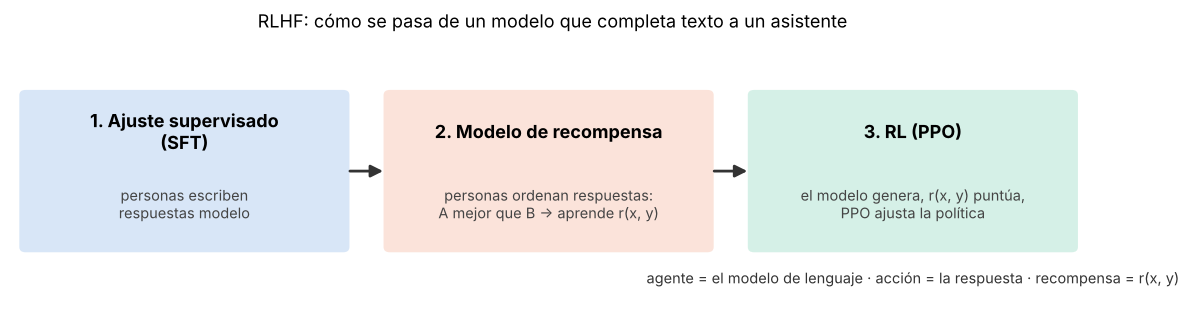

In [17]:
diagrama_rlhf()

Un modelo de lenguaje preentrenado solo sabe **continuar texto**. Para convertirlo en un asistente, el **RL a partir de retroalimentación humana** (*RL from human feedback*, RLHF; Ouyang et al., 2022, InstructGPT) hace tres cosas: (1) lo ajusta con ejemplos de buenas respuestas escritas por personas (*supervised fine-tuning*, SFT; es aprendizaje por imitación); (2) le muestra a personas varias respuestas a la misma pregunta, ellas las **ordenan**, y con esos rankings entrena una red que predice cuánto le va a gustar a una persona una respuesta: el **modelo de recompensa** $r(x, y)$; (3) usa RL (el algoritmo PPO, *proximal policy optimization*) para que el modelo genere respuestas con alta recompensa, con una penalización por alejarse demasiado del modelo original (para que no "engañe" al modelo de recompensa: el *reward hacking* del tutor, otra vez). En lenguaje de este curso: **agente** = el modelo, **acción** = la respuesta, **recompensa** = $r(x, y)$, y cada conversación es un episodio de un paso, como un bandit con un número astronómico de brazos. Por eso decimos que ChatGPT es el ejemplo de RL que más gente usa todos los días.

## 6. Proyecto final: el MDP de su dominio

Cada grupo elige un problema de **su** área (farmacia, laboratorio, marketing, salud, finanzas, docencia…) y lo convierte en un MDP chico que se pueda resolver con `resolver_mdp`. La entrega es este mismo bloque de celdas, completo.

**Plantilla:**

1. **El problema**: ¿quién decide, qué decide, cada cuánto?
2. **Estados**: ¿qué hay que saber para decidir? (¿es Markov?) Pocos: entre 3 y 30.
3. **Acciones**: entre 2 y 5.
4. **Dinámica**: para cada estado y acción, a qué estados se puede pasar y con qué probabilidad.
5. **Recompensa**: ¿qué número refleja lo que **de verdad** queremos? ¿Cómo podría el agente hacer trampa?
6. **Resolver y mirar**: la tabla de la política, ¿tiene sentido? ¿Qué parámetro la hace cambiar?

### Ejemplo resuelto — Stock de un medicamento en la farmacia

- **Estado**: unidades en stock al cerrar el día (0 a 6).
- **Acciones**: pedir 0, 2 o 4 unidades a la droguería (llegan para el día siguiente).
- **Dinámica**: la demanda diaria es 0, 1, 2 o 3 unidades con probabilidades 0.2, 0.4, 0.3, 0.1.
- **Recompensa**: +3 por unidad vendida, −1 por unidad pedida, −0.5 de costo fijo por pedido, −0.2 por unidad guardada, −2 por cada paciente que se va sin el medicamento.

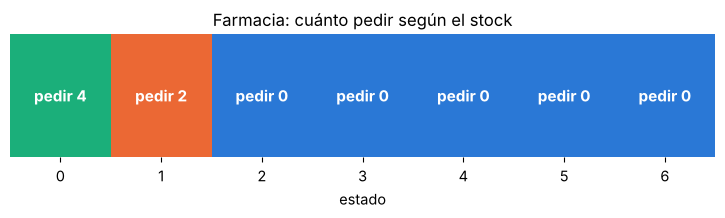

,estado,acción óptima,valor V(s),"Q(s, pedir 0)","Q(s, pedir 2)","Q(s, pedir 4)"
0,0,pedir 4,36.47,32.05,36.23,36.47
1,1,pedir 2,37.55,36.21,37.55,37.26
2,2,pedir 0,38.73,38.73,38.47,37.86
3,3,pedir 0,40.05,40.05,39.26,NaN
4,4,pedir 0,40.97,40.97,39.86,NaN
5,5,pedir 0,41.76,41.76,NaN,NaN
6,6,pedir 0,42.36,42.36,NaN,NaN


In [18]:
ESTADOS = list(range(0, 7))                       # unidades en stock
ACCIONES = ["pedir 0", "pedir 2", "pedir 4"]
DEMANDA = {0: 0.2, 1: 0.4, 2: 0.3, 3: 0.1}
STOCK_MAX = 6

def transicion(s, a):
    pedido = int(a.split()[1])
    if s + pedido > STOCK_MAX:
        return []                                 # no entra en la estantería: acción no permitida
    resultado = []
    for demanda, p in DEMANDA.items():
        disponible = s + pedido
        vendidas = min(disponible, demanda)
        faltante = demanda - vendidas
        s_sig = disponible - vendidas
        r = 3 * vendidas - 1 * pedido - 0.5 * (pedido > 0) - 0.2 * s_sig - 2 * faltante
        resultado.append((p, s_sig, r))
    return resultado

resolver_mdp(ESTADOS, ACCIONES, transicion, gamma=0.95, titulo="Farmacia: cuánto pedir según el stock")

La política es la clásica regla "(s, S)" de inventarios: **con poco stock, pedir; con suficiente, no pedir**. Nadie se la enseñó: sale de la recompensa.

### ✍️ Ejercicio — Su proyecto

Completen las celdas siguientes con su MDP (copien la estructura del ejemplo). Preguntas para la presentación: ¿qué parámetro cambia la política? ¿cómo podría el agente "hacer trampa" con su recompensa?

**1–5. Problema, estados, acciones, dinámica, recompensa** (describir acá en texto):

- Problema:
- Estados:
- Acciones:
- Dinámica:
- Recompensa:

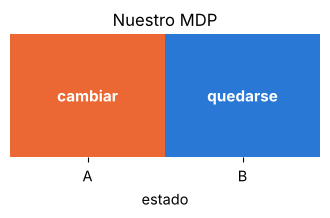

,estado,acción óptima,valor V(s),"Q(s, quedarse)","Q(s, cambiar)"
0,A,cambiar,8.78,7.9,8.78
1,B,quedarse,10.00,10.0,8.12


In [19]:
# TODO: reemplazar por el MDP del grupo
MIS_ESTADOS = ["A", "B"]
MIS_ACCIONES = ["quedarse", "cambiar"]

def mi_transicion(s, a):
    # devolver una lista de (probabilidad, estado_siguiente, recompensa)
    otro = "B" if s == "A" else "A"
    if a == "quedarse":
        return [(1.0, s, 1.0 if s == "B" else 0.0)]
    return [(0.8, otro, 0.0), (0.2, s, 0.0)]

resolver_mdp(MIS_ESTADOS, MIS_ACCIONES, mi_transicion, gamma=0.9, titulo="Nuestro MDP")

**6. Lo que encontramos** (¿la política tiene sentido? ¿qué parámetro la cambia? ¿cómo se podría hacer trampa con la recompensa?):

-

## Ejemplo resuelto: la difusión de este curso como bandit

El proyecto final pide plantear un problema propio como MDP. Este es el ejemplo resuelto: **cómo se propaga este curso**. El curso es un replicador (un *meme* en el sentido de Dawkins): vive solo si alguien lo aprende y se lo enseña a otra persona. Su campaña de Instagram es un bandit.

| | |
|---|---|
| **Agente** | el curso, que elige qué publicar |
| **Acciones (brazos)** | cuatro tipos de post: *intriga*, *concepto*, *demo interactiva*, *invitación a enseñar* |
| **Estado** | el acto de la campaña (I, II, III) y la audiencia alcanzada; lo ignoramos y tratamos el problema como bandit (un solo estado) |
| **Recompensa** | propagación por cada mil personas alcanzadas |

**La recompensa de un meme.** Un replicador sobrevive si se copia con **fidelidad**, **fecundidad** y **longevidad**. Cada una tiene una métrica de Instagram o de GitHub:

- **guardado** → longevidad (la persona vuelve a mirarlo): peso $w_g = 1$
- **compartido** → fecundidad (llega a alguien más): peso $w_c = 3$
- **visita al repositorio** → fidelidad (va a la fuente completa, no a un resumen): peso $w_v = 5$

$$r = 1000 \cdot \frac{w_g \cdot \text{guardados} + w_c \cdot \text{compartidos} + w_v \cdot \text{visitas}}{\text{alcance}}$$

**Política.** Los primeros 4 posts exploran (uno de cada tipo). Desde el quinto, **Thompson sampling**: cada tipo tiene una creencia Beta sobre su "tasa de propagación por persona"; se sortea un valor de cada una y se publica el tipo que salió más alto. Como la recompensa no es 0/1, contamos como "éxitos" la recompensa ponderada dividida por el peso mayor (una aproximación razonable para tasas chicas).

> ⚠️ **Las tasas de abajo son SUPUESTAS** (inventadas para ilustrar). Más abajo hay una celda para pegar las métricas reales de cada post.

In [20]:
TIPOS = ["intriga", "concepto", "demo", "ensenar"]
PESOS = np.array([1.0, 3.0, 5.0])          # guardado (longevidad), compartido (fecundidad), visita al repo (fidelidad)

# ⚠️ SUPUESTO: tasas por persona alcanzada [guardado, compartido, visita al repo]. No son datos reales.
TASAS_SUPUESTAS = np.array([
    [0.015, 0.006, 0.002],   # intriga
    [0.030, 0.005, 0.004],   # concepto
    [0.025, 0.012, 0.008],   # demo interactiva
    [0.018, 0.015, 0.006],   # invitación a enseñar
])
ALCANCE = 500                                # ⚠️ SUPUESTO: personas alcanzadas por post

r_esperada = 1000 * TASAS_SUPUESTAS @ PESOS
for t, r in zip(TIPOS, r_esperada):
    print(f"{t:10s} recompensa esperada por 1000 alcanzados: {r:6.1f}")

intriga    recompensa esperada por 1000 alcanzados:   43.0
concepto   recompensa esperada por 1000 alcanzados:   65.0
demo       recompensa esperada por 1000 alcanzados:  101.0
ensenar    recompensa esperada por 1000 alcanzados:   93.0


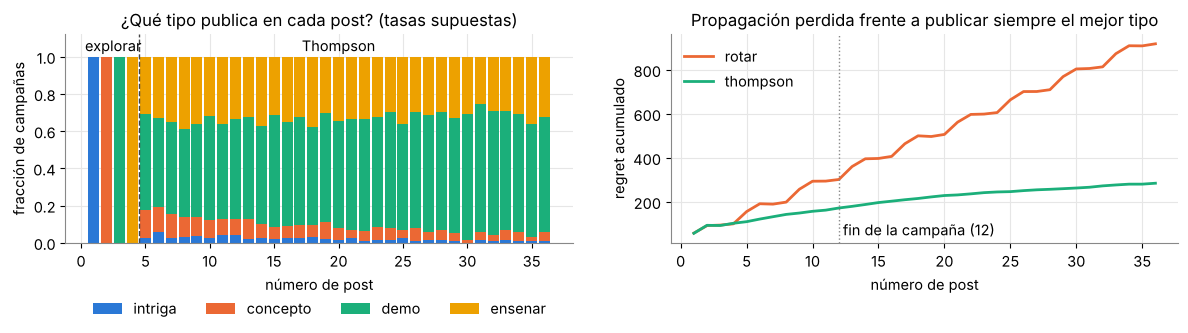

Con 12 posts, Thompson eligió el mejor tipo (demo) en el post 12 en el 54% de las campañas.


In [21]:
def campania(n_posts, rng, politica="thompson"):
    # Simula una campaña: devuelve los tipos elegidos y la recompensa de cada post.
    wmax = PESOS.max()
    a_beta, b_beta = np.ones(4), np.ones(4)
    elegidos, recompensas = [], []
    for k in range(n_posts):
        if k < 4 or politica == "rotar":
            a = k % 4                                       # explorar: uno de cada tipo (o rotar siempre)
        else:
            a = int(np.argmax(rng.beta(a_beta, b_beta)))    # Thompson sampling
        conteos = rng.binomial(ALCANCE, TASAS_SUPUESTAS[a])  # guardados, compartidos, visitas
        exitos = conteos @ PESOS / wmax
        a_beta[a] += exitos
        b_beta[a] += ALCANCE - exitos
        elegidos.append(a)
        recompensas.append(1000 * conteos @ PESOS / ALCANCE)
    return np.array(elegidos), np.array(recompensas)


def comparar_campanias(n_posts=36, n_sim=300, seed=0):
    rng = np.random.default_rng(seed)
    elig = np.array([campania(n_posts, rng)[0] for _ in range(n_sim)])
    regret = {}
    for pol in ("rotar", "thompson"):
        rr = np.array([campania(n_posts, rng, pol)[1] for _ in range(n_sim)])
        regret[pol] = np.cumsum(r_esperada.max() - rr, axis=1).mean(0)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    x = np.arange(1, n_posts + 1)
    abajo = np.zeros(n_posts)
    for i, t in enumerate(TIPOS):
        frac = (elig == i).mean(0)
        ax[0].bar(x, frac, bottom=abajo, color=COLORES[i], label=t, width=0.85)
        abajo += frac
    ax[0].axvline(4.5, color="#444", ls="--", lw=1)
    ax[0].text(2.5, 1.03, "explorar", ha="center"); ax[0].text(min(20, n_posts * 0.6), 1.03, "Thompson", ha="center")
    ax[0].set_xlabel("número de post"); ax[0].set_ylabel("fracción de campañas"); ax[0].set_ylim(0, 1.12)
    ax[0].legend(ncols=4, loc="lower center", bbox_to_anchor=(0.5, -0.42), frameon=False)
    ax[0].set_title("¿Qué tipo publica en cada post? (tasas supuestas)")
    for pol, c in (("rotar", COLORES[1]), ("thompson", COLORES[2])):
        ax[1].plot(x, regret[pol], color=c, label=pol)
    ax[1].axvline(12, color="#888", ls=":", lw=1); ax[1].text(12.3, ax[1].get_ylim()[1] * 0.05, "fin de la campaña (12)")
    ax[1].set_xlabel("número de post"); ax[1].set_ylabel("regret acumulado"); ax[1].legend(frameon=False)
    ax[1].set_title("Propagación perdida frente a publicar siempre el mejor tipo")
    plt.tight_layout(); plt.show()
    print(f"Con 12 posts, Thompson eligió el mejor tipo (demo) en el post 12 en el {np.mean(elig[:, 11] == 2):.0%} de las campañas.")


comparar_campanias(n_posts=36, n_sim=300, seed=SEMILLA)

**Qué mirar:**

- En los posts 1 a 4 todas las campañas publican lo mismo: uno de cada tipo.
- Desde el 5, Thompson se concentra en **demo** y en **invitación a enseñar**, que con estas tasas supuestas son parecidas; casi abandona *intriga*, que es claramente peor.
- Con solo 12 posts la duda entre los dos mejores no se resuelve del todo: por eso Thompson los sigue alternando. Rotar los cuatro tipos para siempre pierde propagación a ritmo constante.

### Las métricas reales

Pegá en la celda de abajo lo que muestra Instagram para cada post a los 7 días (alcance, guardados, compartidos) y las visitas al repositorio que dé GitHub (*Insights → Traffic*). La página `difusion/estrategia.html` del sitio tiene un botón **"Copiar para el notebook"** que genera esta lista con el formato correcto. Si la lista queda vacía, se usa un ejemplo **supuesto**.

In [22]:
# ✍️ Pegar acá las métricas reales: (tipo, alcance, guardados, compartidos, visitas_repo)
# tipo ∈ "intriga", "concepto", "demo", "ensenar"
MIS_METRICAS = [
    # ("intriga", 820, 14, 5, 1),
]

In [23]:
# ⚠️ EJEMPLO SUPUESTO (no son datos reales): se usa solo si MIS_METRICAS está vacía
EJEMPLO_SUPUESTO = [
    ("intriga", 820, 14, 5, 1), ("concepto", 760, 11, 4, 2), ("demo", 900, 16, 6, 1), ("ensenar", 1100, 19, 9, 3),
    ("concepto", 950, 30, 6, 4), ("demo", 1300, 34, 17, 11), ("demo", 1250, 30, 15, 10), ("concepto", 880, 25, 4, 3),
    ("intriga", 870, 27, 5, 4), ("ensenar", 1400, 26, 22, 9), ("demo", 1500, 39, 19, 13), ("ensenar", 1700, 31, 27, 12),
]


def analizar(metricas, pesos=PESOS, n_mc=20000, seed=0):
    df = pd.DataFrame(metricas, columns=["tipo", "alcance", "guardados", "compartidos", "visitas_repo"])
    df.index = np.arange(1, len(df) + 1); df.index.name = "post"
    pond = df[["guardados", "compartidos", "visitas_repo"]].to_numpy() @ pesos
    df["r_por_1000"] = (1000 * pond / df["alcance"]).round(1)
    df["exitos"] = pond / pesos.max()
    rng = np.random.default_rng(seed)
    filas, muestras = [], []
    for t in TIPOS:
        d = df[df["tipo"] == t]
        a, b = 1 + d["exitos"].sum(), 1 + (d["alcance"] - d["exitos"]).sum()
        muestras.append(rng.beta(a, b, n_mc))
        filas.append({"tipo": t, "posts": len(d), "r medio": d["r_por_1000"].mean() if len(d) else np.nan})
    gana = np.argmax(np.array(muestras), axis=0)
    resumen = pd.DataFrame(filas).set_index("tipo")
    resumen["P(mejor)"] = [np.mean(gana == i) for i in range(4)]
    display(df.drop(columns="exitos"))
    display(resumen.style.format({"r medio": "{:.1f}", "P(mejor)": "{:.0%}"}))
    faltan = resumen.index[resumen["posts"] == 0].tolist()
    if faltan:
        print("Seguir explorando: faltan probar", ", ".join(faltan))
    else:
        mejor = resumen["P(mejor)"].idxmax()
        print(f"Conviene repetir: {mejor} (probabilidad de ser el mejor: {resumen.loc[mejor, 'P(mejor)']:.0%})")
        siguiente = TIPOS[int(np.argmax([m[0] for m in muestras]))]
        print(f"Un sorteo de Thompson para el próximo post elige: {siguiente}")
    return df, resumen


if MIS_METRICAS:
    datos = MIS_METRICAS
else:
    print("⚠️ MIS_METRICAS está vacía: se usa el EJEMPLO SUPUESTO.\n")
    datos = EJEMPLO_SUPUESTO
_ = analizar(datos)

⚠️ MIS_METRICAS está vacía: se usa el EJEMPLO SUPUESTO.



,tipo,alcance,guardados,compartidos,visitas_repo,r_por_1000
post,,,,,,
1,intriga,820,14,5,1,41.5
2,concepto,760,11,4,2,43.4
3,demo,900,16,6,1,43.3
4,ensenar,1100,19,9,3,55.5
5,concepto,950,30,6,4,71.6
6,demo,1300,34,17,11,107.7
7,demo,1250,30,15,10,100.0
8,concepto,880,25,4,3,59.1
9,intriga,870,27,5,4,71.3


,posts,r medio,P(mejor)
tipo,,,
intriga,2,56.4,1%
concepto,3,58.0,1%
demo,4,89.6,65%
ensenar,3,84.9,34%


Conviene repetir: demo (probabilidad de ser el mejor: 65%)
Un sorteo de Thompson para el próximo post elige: demo


**Para pensar:** si mañana el peso de los compartidos fuera 0, ¿cambia el tipo recomendado? ¿Qué recompensa haría que este curso se "hackee" a sí mismo, como el tutor que solo da sumas (por ejemplo, premiar alcance sin importar si alguien aprendió)? La página `difusion/estrategia.html` muestra la misma idea con una red de personas que crece según la fidelidad, la fecundidad y la longevidad del curso.

## Preguntas para pensar

1. En el bandit de anuncios la recompensa es el clic. ¿Qué anuncio aprendería a mostrar un algoritmo que maximiza clics si existiera un anuncio engañoso (*clickbait*)? ¿Qué tiene en común con el tutor que solo da sumas?
2. En *deep search*, ¿quién decide el costo por paso? ¿Qué pasaría con un agente al que nunca se le cobra por buscar?
3. En RLHF, la recompensa la aprende una red a partir de preferencias humanas. ¿Qué preferencias humanas podría estar aprendiendo que no queremos (por ejemplo, respuestas largas, seguras de sí mismas, aduladoras)?

## Próxima clase

En la clase 9 el agente sale al mundo real, donde no hay simulador para jugar un millón de veces. Y es algo que ya usan: cada vez que conversan con un modelo de lenguaje están hablando con una política entrenada con RL. Lo que sigue (DPO, RL con recompensas verificables en modelos que razonan, agentes con herramientas) es la misma receta: estado, acción, recompensa… y mucho cuidado con lo que se le pide.